# Classification Track (Part A + Part B)
**Dataset:** Mobile Price Classification (`data/train.csv`): 2,000 phones, 20 features, target `price_range` with 4 classes (0 = low cost, 1 = medium, 2 = high, 3 = very high).

**Goal:** train the 10 algorithms from guideline section 3.2 on the same preprocessed data and the same held-out test set, compare them on all mandatory metrics, tune them, and select a final model.

| Part A (Review 1) | Part B (Review 2) |
|---|---|
| Logistic Regression | Random Forest |
| K-Nearest Neighbors | AdaBoost |
| Naive Bayes (Gaussian) | Gradient Boosting (sklearn GBM) |
| Decision Tree | Bagging (Decision Tree base estimator) |
| SVC | MLP (neural network) |

**Mandatory metrics:** Accuracy, weighted Precision, weighted Recall, weighted F1, confusion matrix, and one-vs-rest ROC-AUC (multi-class).

In [1]:
# Make the project's src/ package importable from notebooks/
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 80)

## 1. Load and audit the data
Shape, data types, missing values and class distribution.

In [2]:
from src import config as C, data_loader as dl, classification as clf, visualize as viz

df = dl.load_classification()
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('\nClass distribution:')
print(df[C.TARGET_COL].value_counts().sort_index())
df.dtypes.value_counts()

Shape: (2000, 21)
Missing values: 0
Duplicate rows: 0

Class distribution:
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


int64      19
float64     2
Name: count, dtype: int64

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.5185,439.4182,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.4950,0.5001,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.5223,0.8160,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.5095,0.5000,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.3095,4.3414,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.5215,0.4997,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.0465,18.1457,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.5018,0.2884,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.2490,35.3997,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.5205,2.2878,1.0,3.00,4.0,7.00,8.0


## 2. Train/test split and preprocessing
- Stratified 80/20 split with `random_state=42`, shared by all 10 models.
- Every model is a `Pipeline(StandardScaler → model)`, so the scaler is fitted on the training data only, and inside cross-validation it is re-fitted on each training fold (no leakage).

In [4]:
X_train, X_test, y_train, y_test = dl.split_classification(df)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train class counts:', np.bincount(y_train), ' Test class counts:', np.bincount(y_test))

Train: (1600, 20)  Test: (400, 20)
Train class counts: [400 400 400 400]  Test class counts: [100 100 100 100]


## 3. Baseline: all 10 models with default settings
Each model is trained on the training set and evaluated on the same test set. The table is ranked by weighted F1.

In [5]:
baseline, fitted = clf.train_and_compare(X_train, X_test, y_train, y_test)
baseline

,Model,Part,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (OvR),Train time (s)
1,Logistic Regression,A (Review 1),0.9650,0.9650,0.9650,0.9650,0.9987,0.031
2,MLP (Neural Net),B (Review 2),0.9275,0.9286,0.9275,0.9275,0.9941,1.564
3,Gradient Boosting,B (Review 2),0.9125,0.9124,0.9125,0.9123,0.9896,1.783
4,Bagging,B (Review 2),0.8975,0.8978,0.8975,0.8976,0.9877,1.936
5,SVM (SVC),A (Review 1),0.8950,0.8969,0.8950,0.8956,0.9833,0.451
6,Random Forest,B (Review 2),0.8800,0.8796,0.8800,0.8797,0.9767,0.349
7,Decision Tree,A (Review 1),0.8300,0.8319,0.8300,0.8302,0.8867,0.028
8,Naive Bayes,A (Review 1),0.8100,0.8113,0.8100,0.8105,0.9506,0.021
9,KNN,A (Review 1),0.5000,0.5211,0.5000,0.5054,0.7697,0.138
10,AdaBoost,B (Review 2),0.4900,0.4831,0.4900,0.4437,0.8200,0.190


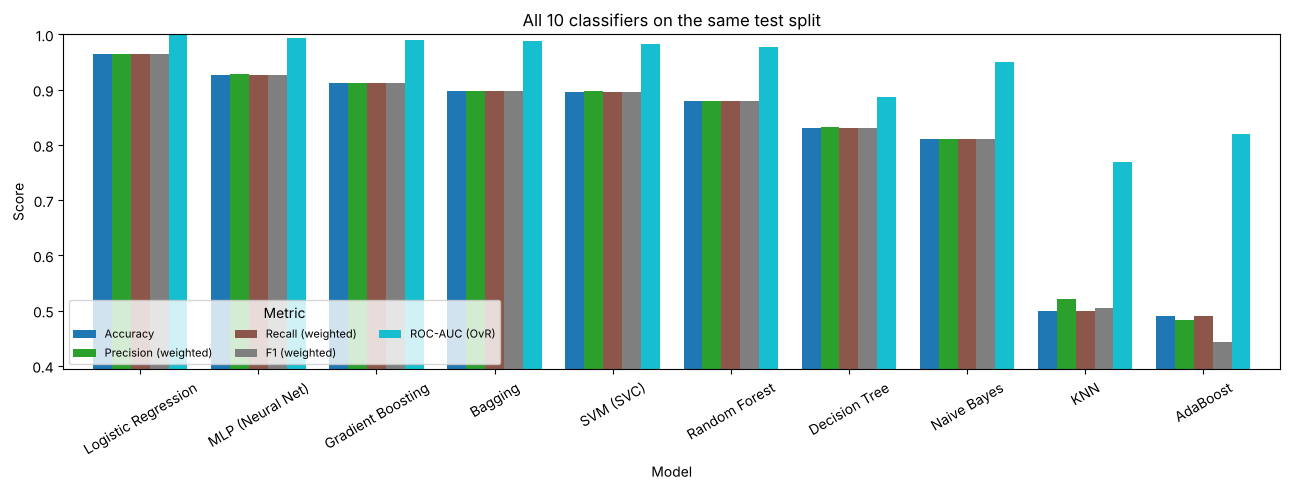

In [6]:
viz.classifier_comparison(baseline, clf.METRICS);

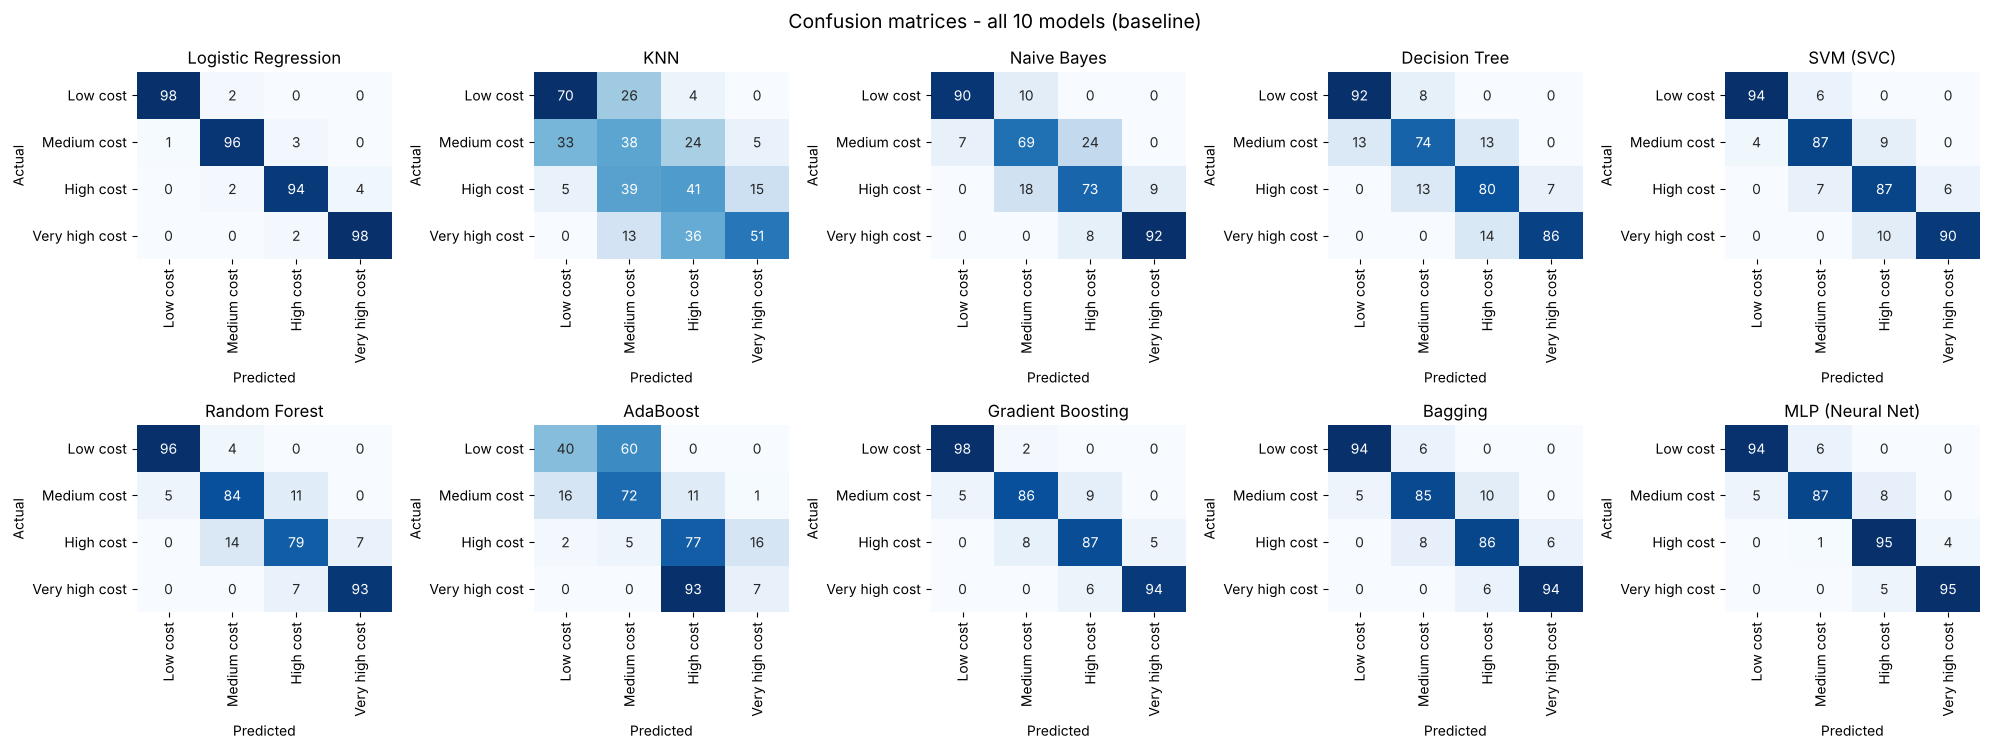

In [7]:
labels = [C.PRICE_LABELS[i] for i in range(4)]
viz.confusion_grid({n: clf.confusion(m, X_test, y_test) for n, m in fitted.items()},
                   labels, 'Confusion matrices - all 10 models (baseline)');

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Which models perform best and worst at baseline, and by how much?
> - What could explain the weakest models' scores? (Consider how each algorithm works and the effect of scaling.)
> - What do the confusion matrices show about which classes get confused?
>
> _Your answer here._

## 4. Hyperparameter tuning (all 10 models)
5-fold stratified `GridSearchCV` on weighted F1. The search spaces follow the notes in guideline 3.2:

| Model | Parameters searched |
|---|---|
| Logistic Regression | C |
| KNN | n_neighbors, metric |
| Naive Bayes | var_smoothing |
| Decision Tree | max_depth, min_samples_leaf |
| SVM (SVC) | C, kernel |
| Random Forest | n_estimators, max_depth |
| AdaBoost | n_estimators, learning_rate, estimator |
| Gradient Boosting | n_estimators, learning_rate, max_depth |
| Bagging | n_estimators, max_samples, max_features |
| MLP (Neural Net) | hidden_layer_sizes, activation |

This cell takes a few minutes.

In [8]:
tuned, rows = {}, []
for name in baseline['Model']:
    gs = clf.tune(name, X_train, y_train)
    tuned[name] = gs
    after = clf.evaluate(gs.best_estimator_, X_test, y_test)
    before = baseline.set_index('Model').loc[name]
    rows.append({'Model': name, 'Part': clf.part_of(name),
                 'Best params': clf.readable_params(gs.best_params_),
                 'CV F1 (5-fold)': gs.best_score_,
                 'CV F1 std': gs.cv_results_['std_test_score'][gs.best_index_],
                 'F1 before': before['F1 (weighted)'], 'F1 after': after['F1 (weighted)'],
                 'Accuracy before': before['Accuracy'], 'Accuracy after': after['Accuracy']})
tuning = pd.DataFrame(rows).sort_values('CV F1 (5-fold)', ascending=False).reset_index(drop=True)
tuning.index += 1
tuning

,Model,Part,Best params,CV F1 (5-fold),CV F1 std,F1 before,F1 after,Accuracy before,Accuracy after
1,SVM (SVC),A (Review 1),"C=10, kernel=linear",0.9650,0.0068,0.8956,0.9750,0.8950,0.9750
2,Logistic Regression,A (Review 1),C=100,0.9632,0.0054,0.9650,0.9825,0.9650,0.9825
3,MLP (Neural Net),B (Review 2),"activation=tanh, hidden_layer_sizes=(128, 64)",0.9549,0.0048,0.9275,0.9575,0.9275,0.9575
4,AdaBoost,B (Review 2),"estimator=DecisionTree(max_depth=3), learning_rate=0.5, n_estimators=200",0.9199,0.0180,0.4437,0.9377,0.4900,0.9375
5,Gradient Boosting,B (Review 2),"learning_rate=0.1, max_depth=2, n_estimators=300",0.9034,0.0170,0.9123,0.9374,0.9125,0.9375
6,Bagging,B (Review 2),"max_features=1.0, max_samples=1.0, n_estimators=100",0.8868,0.0185,0.8976,0.8976,0.8975,0.8975
7,Random Forest,B (Review 2),"max_depth=10, n_estimators=300",0.8728,0.0297,0.8797,0.8872,0.8800,0.8875
8,Decision Tree,A (Review 1),"max_depth=8, min_samples_leaf=10",0.8372,0.0158,0.8302,0.8370,0.8300,0.8375
9,Naive Bayes,A (Review 1),var_smoothing=1e-11,0.8044,0.0271,0.8105,0.8105,0.8100,0.8100
10,KNN,A (Review 1),"metric=manhattan, n_neighbors=31",0.6639,0.0168,0.5054,0.7203,0.5000,0.7200


## 5. Consolidated comparison table: all 10 algorithms (after tuning)
This is the single table required by rubric A2 and deliverable D6.

In [9]:
final = pd.DataFrame([{'Model': n, 'Part': clf.part_of(n), **clf.evaluate(gs.best_estimator_, X_test, y_test)}
                      for n, gs in tuned.items()])
final = final.sort_values(['F1 (weighted)', 'Accuracy'], ascending=False).reset_index(drop=True)
final.index += 1
final

,Model,Part,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (OvR)
1,Logistic Regression,A (Review 1),0.9825,0.9826,0.9825,0.9825,0.9991
2,SVM (SVC),A (Review 1),0.9750,0.9750,0.9750,0.9750,0.9994
3,MLP (Neural Net),B (Review 2),0.9575,0.9576,0.9575,0.9575,0.9980
4,AdaBoost,B (Review 2),0.9375,0.9383,0.9375,0.9377,0.9933
5,Gradient Boosting,B (Review 2),0.9375,0.9374,0.9375,0.9374,0.9923
6,Bagging,B (Review 2),0.8975,0.8978,0.8975,0.8976,0.9877
7,Random Forest,B (Review 2),0.8875,0.8876,0.8875,0.8872,0.9804
8,Decision Tree,A (Review 1),0.8375,0.8367,0.8375,0.8370,0.9511
9,Naive Bayes,A (Review 1),0.8100,0.8113,0.8100,0.8105,0.9506
10,KNN,A (Review 1),0.7200,0.7219,0.7200,0.7203,0.8792


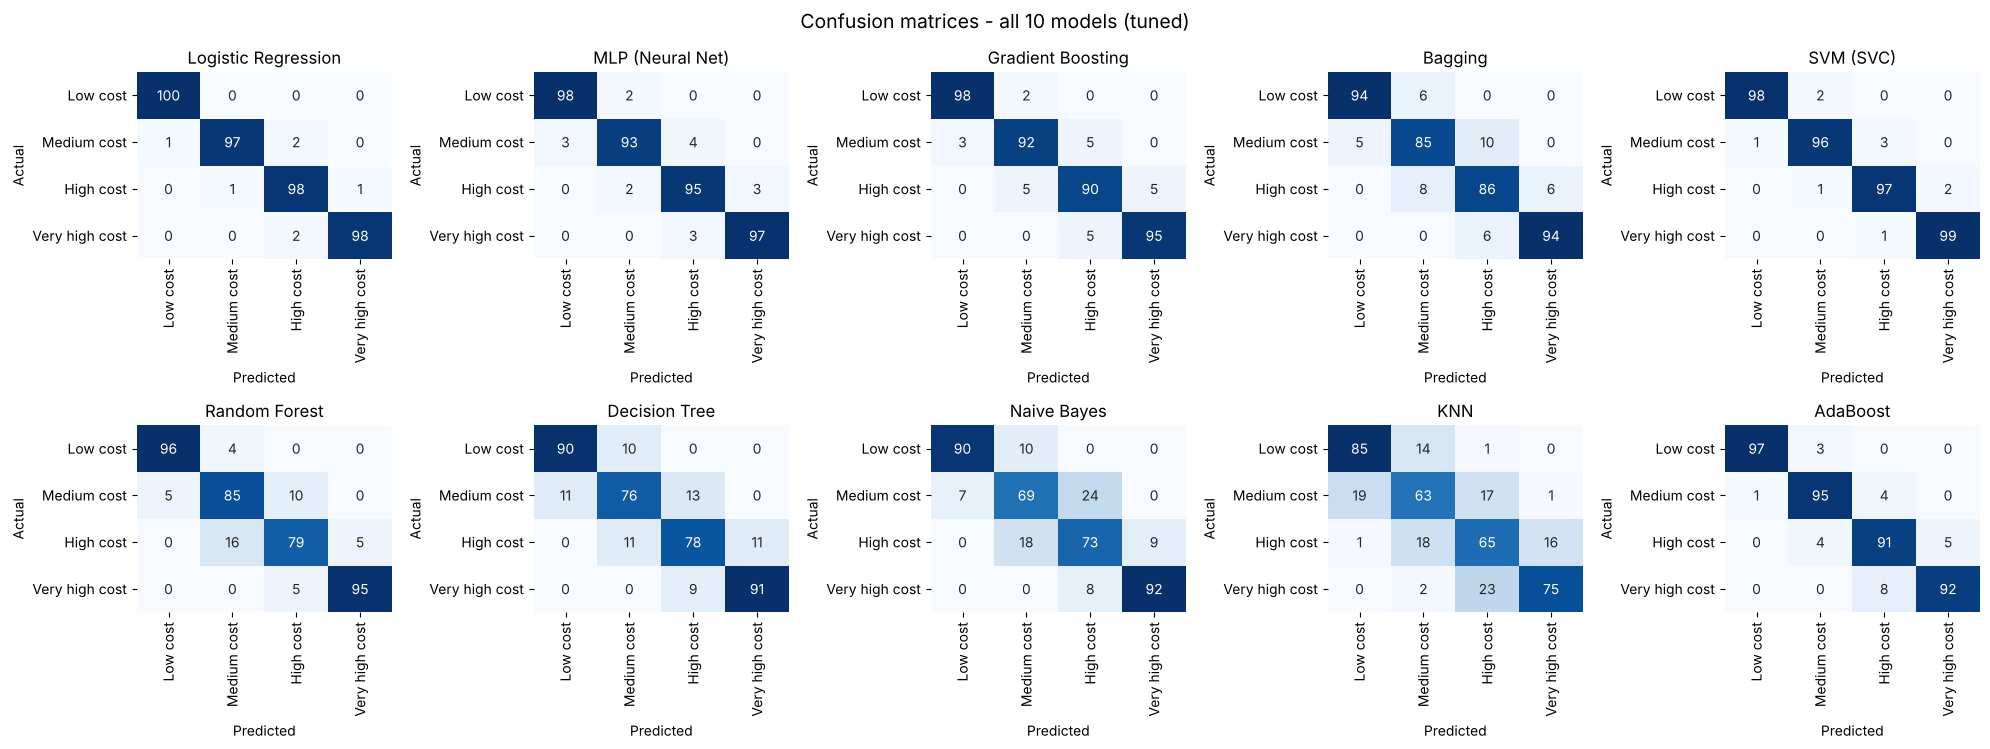

In [10]:
viz.confusion_grid({n: clf.confusion(gs.best_estimator_, X_test, y_test) for n, gs in tuned.items()},
                   labels, 'Confusion matrices - all 10 models (tuned)');

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Which models improved most from tuning, and which parameters made the difference?
> - Did any model's ranking change after tuning? Why might that be?
>
> _Your answer here._

## 6. Final model selection
The final model is the one with the highest **cross-validated** weighted F1, so the test set is not used to choose it.

In [11]:
best_name = tuning['Model'].iloc[0]
best = tuned[best_name].best_estimator_
print('Selected model:', best_name)
print('Best parameters:', clf.readable_params(tuned[best_name].best_params_))
pd.DataFrame([baseline.set_index('Model').loc[best_name, clf.METRICS].astype(float).to_dict(),
              clf.evaluate(best, X_test, y_test)], index=['baseline', 'tuned'])

Selected model: SVM (SVC)
Best parameters: C=10, kernel=linear


,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (OvR)
baseline,0.895,0.8969,0.895,0.8956,0.9833
tuned,0.975,0.9750,0.975,0.9750,0.9994


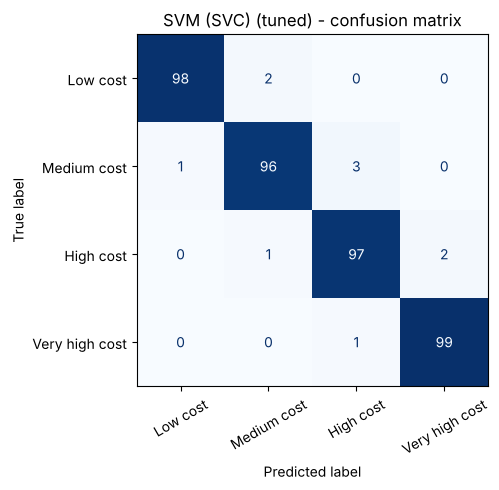

In [12]:
viz.confusion(best, X_test, y_test, f'{best_name} (tuned) - confusion matrix', labels);

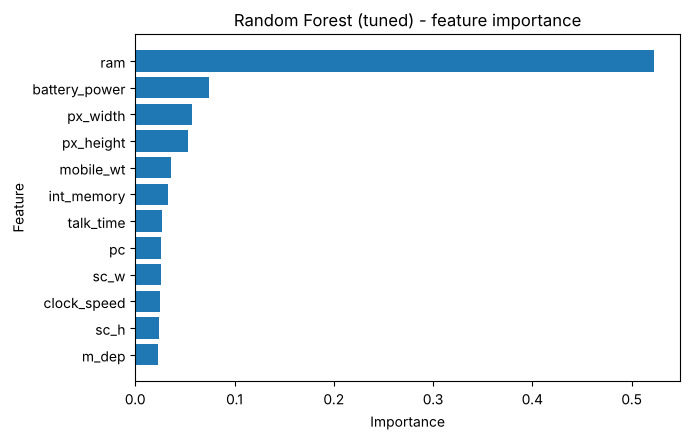

In [13]:
viz.feature_importance(tuned['Random Forest'].best_estimator_, X_train.columns,
                       'Random Forest (tuned) - feature importance');

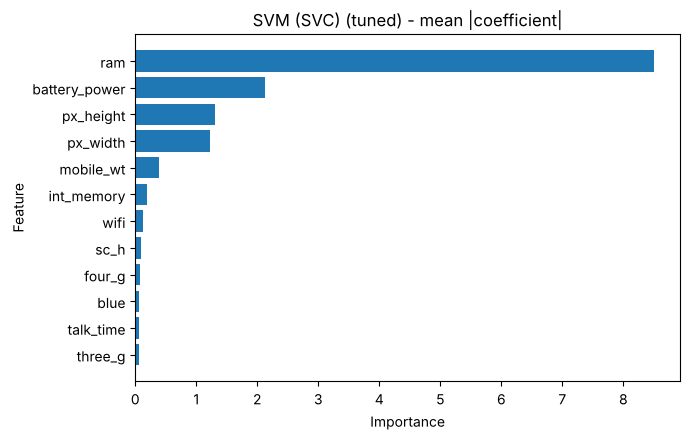

In [14]:
viz.feature_importance(best, X_train.columns, f'{best_name} (tuned) - mean |coefficient|');

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Justify the final model choice: compare its CV score with the runner-up (look at the CV std too).
> - Which features matter most, and does that make sense for phone prices?
> - What trade-offs (accuracy, interpretability, training time) did you consider?
>
> _Your answer here._

In [15]:
clf.save_model(best, X_train.columns, best_name, clf.evaluate(best, X_test, y_test))

PosixPath('/home/claude/ml-review2/models/best_classifier.joblib')